# Marketing A/B Test: Did the Ad Campaign Actually Pay Off?

**Dataset:** Kaggle *Marketing A/B Testing* (`marketing_AB.csv`), 588,101 users, Ad group vs PSA (control) group
**Tools:** Python, pandas, SciPy, statsmodels, matplotlib
**Question:** Does showing the ad increase conversions, by how much, and is the campaign worth running at a realistic cost?

## Executive Summary

**Bottom line:** the Ad group has a higher conversion rate than the PSA control group, but the campaign is only profitable if each conversion is worth more than roughly **₹1,600** (at the assumed ₹0.50 per impression) or if ads can be bought for less than roughly **₹0.08 per impression** (at an assumed ₹250 per conversion).

| Question | Answer |
|---|---|
| Is the experiment valid? | Yes. Group split is 96.0% / 4.0% as designed (SRM test p = 0.9998). |
| Does the Ad group convert better than PSA? | Yes. Ad **2.55%** vs PSA **1.79%** (+0.77 percentage points, **+43% relative lift**). |
| How certain is it? | 95% CI for the difference: **+0.60 to +0.94 pp**. Two-proportion z-test p = 1.7e-13. Bootstrap agrees (+0.59 to +0.94 pp). |
| Was the test big enough? | Yes. Minimum detectable effect was 0.26 pp, much smaller than the 0.77 pp observed. |
| How many extra conversions? | About **4,343** incremental conversions (roughly 3,360 to 5,326 using the CI). |
| Is it profitable? | **Depends on unit economics.** At the assumed ₹0.50 per impression, ROI is negative in all three value scenarios. Break-even is ₹1,613 per incremental conversion. |
| Does lift hold across segments? | Yes across all four time-of-day blocks and 4 of 7 days after multiple-testing correction (Friday is borderline; Thursday and Sunday show no reliable lift). |

**Recommendation**
1. Keep the ads running only if real margin per conversion exceeds the break-even value, or if the real cost per impression is below the break-even cost. Replace the illustrative assumptions in Section 9 with finance data.
2. Do not treat the "51+ ads" result as proof that more ads cause more conversions (see Section 7). Test frequency caps with a *randomised* experiment first.
3. Low-exposure users (1 to 10 ads) show no significant lift, so spend there is the first place to look for savings.

## Project Overview

### Key Questions
- Is the experiment balanced according to its expected 96% Ad / 4% PSA allocation?
- Does the Ad group convert better than the PSA group, and by how much?
- Is the difference statistically significant and robust to bootstrap validation?
- What effect size could this experiment reliably detect?
- Is the experiment healthy (do the groups look comparable on exposure and timing)?
- How does lift vary by ad-exposure level, day and time of day, once multiple comparisons are handled?
- Does the lift translate into positive business economics?

### Important Limitations
- The dataset has **no revenue or ad-cost data**. Section 9 uses clearly labelled illustrative assumptions.
- `total ads`, `most ads day` and `most ads hour` are **post-treatment** variables (they describe behaviour after assignment). Segment results are descriptive, not causal.
- The control group saw PSAs, not nothing. Results measure *ad vs PSA*, not *ad vs no ad*.

## 1. Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Keep marketing_AB.csv in the same folder as this notebook.
# In Google Colab, upload the file to the session before running this cell.
df = pd.read_csv("marketing_AB.csv")

df.head()


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB


## 2. Data Quality Check

Checking missing values, duplicate user IDs and index-like columns. No rows are removed based on outcomes or group differences.

In [3]:
df.isnull().sum()

Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

In [4]:
df["user id"].nunique(), len(df)

(588101, 588101)

In [5]:
df["Unnamed: 0"].nunique()

588101

`Unnamed: 0` is a sequential index (0 to 588,100) with no analytical value, so it is dropped.

In [6]:
df = df.drop(columns=["Unnamed: 0"])
df.shape

(588101, 6)

**Data quality summary:** 588,101 user-level rows, no missing values, every user ID unique, and no rows removed.

## 3. Experiment Validity: Sample Ratio Mismatch (SRM)

Before comparing outcomes, check that the observed allocation matches the designed 96% Ad / 4% PSA split (chi-square goodness-of-fit, α = 0.05).

In [7]:
df["test group"].value_counts()

test group
ad     564577
psa     23524
Name: count, dtype: int64

In [8]:
from scipy.stats import chisquare

observed = df["test group"].value_counts().reindex(["ad", "psa"])

expected = [
    len(df) * 0.96,
    len(df) * 0.04
]

chi2_stat, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

print("Chi-square statistic:", chi2_stat)
print("p-value:", p_value)

Chi-square statistic: 7.084950828432072e-08
p-value: 0.9997876225135022


**Result:** Ad = 564,577 (96.0%), PSA = 23,524 (4.0%). Chi-square p = 0.9998, so there is no evidence of sample ratio mismatch. The allocation is consistent with the design.

## 4. Primary Result: Conversion Rate, Lift and Significance

In [9]:
pd.crosstab(df["test group"], df["converted"])

converted,False,True
test group,,
ad,550154,14423
psa,23104,420


In [10]:
conversion_rate = df.groupby("test group")["converted"].mean() * 100

conversion_rate

test group
ad    2.5547
psa   1.7854
Name: converted, dtype: float64

In [11]:
absolute_difference = conversion_rate["ad"] - conversion_rate["psa"]

relative_lift = (
    (conversion_rate["ad"] - conversion_rate["psa"])
    / conversion_rate["psa"]
) * 100

absolute_difference, relative_lift

(np.float64(0.7692453192201518), np.float64(43.085064022225836))

In [12]:
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest

ad_converted = df.loc[df["test group"] == "ad", "converted"].sum()
ad_total = (df["test group"] == "ad").sum()
psa_converted = df.loc[df["test group"] == "psa", "converted"].sum()
psa_total = (df["test group"] == "psa").sum()

ci_low, ci_high = confint_proportions_2indep(
    ad_converted, ad_total, psa_converted, psa_total, method="wald"
)

print("95% CI lower:", ci_low * 100, "percentage points")
print("95% CI upper:", ci_high * 100, "percentage points")

95% CI lower: 0.5950932431611005 percentage points
95% CI upper: 0.943397395279203 percentage points


In [13]:
z_stat, p_value = proportions_ztest(
    [ad_converted, psa_converted],
    [ad_total, psa_total],
    alternative="two-sided"
)

print("Z-statistic:", z_stat)
print("p-value:", p_value)

Z-statistic: 7.3700781265454145
p-value: 1.7052807161559727e-13


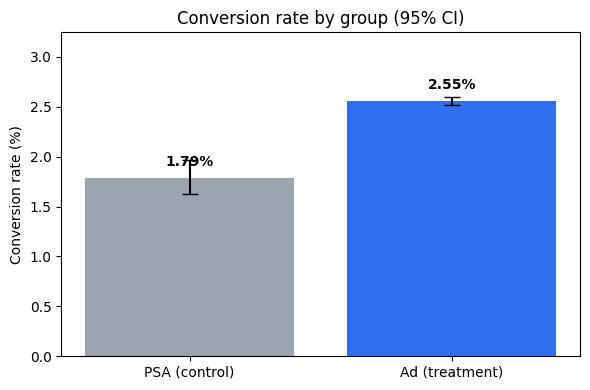

In [14]:
from statsmodels.stats.proportion import proportion_confint

summary = pd.DataFrame({
    "group": ["PSA (control)", "Ad (treatment)"],
    "converted": [psa_converted, ad_converted],
    "users": [psa_total, ad_total],
})
summary["rate"] = summary["converted"] / summary["users"] * 100
ci = [proportion_confint(c, n, method="wilson") for c, n in zip(summary["converted"], summary["users"])]
summary["lo"] = [x[0] * 100 for x in ci]
summary["hi"] = [x[1] * 100 for x in ci]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(summary["group"], summary["rate"],
       yerr=[summary["rate"] - summary["lo"], summary["hi"] - summary["rate"]],
       capsize=6, color=["#9aa5b1", "#2f6fed"])
for i, r in enumerate(summary["rate"]):
    ax.text(i, r + 0.12, f"{r:.2f}%", ha="center", fontweight="bold")
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion rate by group (95% CI)")
ax.set_ylim(0, summary["hi"].max() * 1.25)
plt.tight_layout()
plt.show()

**Interpretation:** the Ad group converts at 2.55% vs 1.79% for PSA, an absolute gain of 0.77 percentage points (a 43% relative lift). The 95% CI (+0.60 to +0.94 pp) excludes zero and the z-test gives p = 1.7e-13. If the documented random assignment was implemented correctly, the overall Ad-versus-PSA difference can be interpreted as the effect of assignment to the Ad condition. It does not estimate Ad versus no advertising.

## 5. Robustness: Bootstrap Validation

Resampling-based validation checks the uncertainty around the conversion-rate difference using 5,000 bootstrap iterations.

In [15]:
# Vectorized nonparametric bootstrap for binary conversion outcomes.
# For binary outcomes, resampling n users with replacement is equivalent to drawing
# the number of conversions from Binomial(n, the observed conversion rate).
np.random.seed(42)

ad_data = df.loc[df["test group"] == "ad", "converted"].astype(int).to_numpy()
psa_data = df.loc[df["test group"] == "psa", "converted"].astype(int).to_numpy()

ad_rate_hat = ad_data.mean()
psa_rate_hat = psa_data.mean()
n_boot = 5000

ad_boot_rates = np.random.binomial(len(ad_data), ad_rate_hat, size=n_boot) / len(ad_data)
psa_boot_rates = np.random.binomial(len(psa_data), psa_rate_hat, size=n_boot) / len(psa_data)
bootstrap_differences = (ad_boot_rates - psa_boot_rates) * 100

print("Bootstrap iterations:", len(bootstrap_differences))
print("Bootstrap mean difference:", bootstrap_differences.mean(), "percentage points")


Bootstrap iterations: 5000
Bootstrap mean difference: 0.7685113176300309 percentage points


In [16]:
bootstrap_ci_low = np.percentile(bootstrap_differences, 2.5)
bootstrap_ci_high = np.percentile(bootstrap_differences, 97.5)

print("Bootstrap 95% CI lower:",
      bootstrap_ci_low, "percentage points")

print("Bootstrap 95% CI upper:",
      bootstrap_ci_high, "percentage points")

Bootstrap 95% CI lower: 0.5919396634351091 percentage points
Bootstrap 95% CI upper: 0.9382216265598661 percentage points


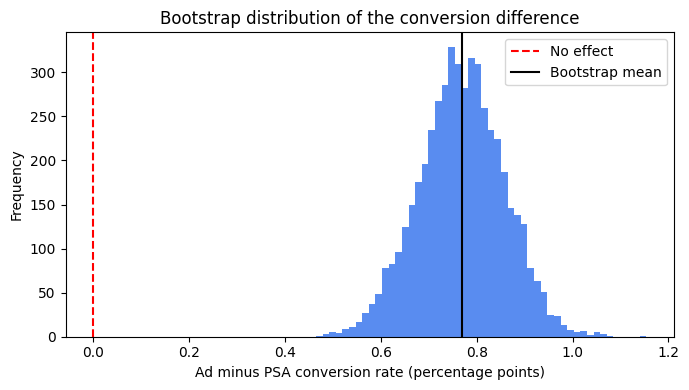

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(bootstrap_differences, bins=50, color="#2f6fed", alpha=0.8)
ax.axvline(0, color="red", linestyle="--", label="No effect")
ax.axvline(bootstrap_differences.mean(), color="black", label="Bootstrap mean")
ax.set_xlabel("Ad minus PSA conversion rate (percentage points)")
ax.set_ylabel("Frequency")
ax.set_title("Bootstrap distribution of the conversion difference")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** the bootstrap interval (+0.59 to +0.94 pp) almost exactly matches the analytical one, and none of the 5,000 resamples falls near zero. The bootstrap interval provides a resampling-based robustness check and closely agrees with the analytical interval.

## 6. Power and Minimum Detectable Effect (MDE)

What is the smallest lift this experiment could reliably detect (80% power, α = 0.05)? The PSA group is the bottleneck because it only has 23,524 users.

In [18]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

baseline_rate = conversion_rate["psa"] / 100

power_analysis = NormalIndPower()

mde = power_analysis.solve_power(
    effect_size=None,
    nobs1=psa_total,
    alpha=0.05,
    power=0.80,
    ratio=ad_total / psa_total,
    alternative="two-sided"
)

print("MDE:", mde)

MDE: 0.018642835121534262


In [19]:
from statsmodels.stats.proportion import proportion_effectsize

baseline = conversion_rate["psa"] / 100
h = mde  # Cohen's h returned by the previous cell

# Convert Cohen's h back to treatment conversion rate
treatment_mde_rate = (
    np.sin(
        np.arcsin(np.sqrt(baseline)) + h / 2
    ) ** 2
)

mde_percentage_points = (treatment_mde_rate - baseline) * 100

mde_relative_percent = (
    (treatment_mde_rate - baseline) / baseline
) * 100

print("Baseline PSA conversion:", baseline * 100, "%")
print("MDE:", mde_percentage_points, "percentage points")
print("MDE relative to PSA:", mde_relative_percent, "%")

Baseline PSA conversion: 1.785410644448223 %
MDE: 0.2552344756625125 percentage points
MDE relative to PSA: 14.295561441630822 %


**Interpretation:** the experiment could reliably detect a lift of about **0.26 pp (14% relative)**. The observed lift (0.77 pp, 43%) is three times larger, so the test was comfortably powered and the finding is not a small-sample fluke.

## 7. Experiment Health Check: Exposure and Timing Balance

Do the two groups look comparable on how much advertising they saw and when? These variables are post-treatment, so differences here are a warning sign to investigate, not proof the test is broken.

In [20]:
df.groupby("test group")["total ads"].describe()

,count,mean,std,min,25%,50%,75%,max
test group,,,,,,,,
ad,"564,577.0000",24.8234,43.7505,1.0000,4.0000,13.0000,27.0000,"2,065.0000"
psa,"23,524.0000",24.7611,42.8607,1.0000,4.0000,12.0000,26.0000,907.0000


In [21]:
pd.crosstab(
    df["most ads day"],
    df["test group"],
    normalize="columns"
) * 100

test group,ad,psa
most ads day,,
Friday,15.7295,16.1665
Monday,14.8024,14.8869
Saturday,13.9577,12.1493
Sunday,14.5830,13.0037
Thursday,14.0064,16.6001
Tuesday,13.2085,12.3576
Wednesday,13.7126,14.8359


In [22]:
from scipy.stats import chi2_contingency

day_table = pd.crosstab(
    df["most ads day"],
    df["test group"]
)

chi2, p_value, dof, expected = chi2_contingency(day_table)

print("Day chi-square:", chi2)
print("Day p-value:", p_value)

Day chi-square: 235.61445227291117
Day p-value: 4.849067664297987e-48


In [23]:
hour_table = pd.crosstab(
    df["most ads hour"],
    df["test group"]
)

chi2, p_value, dof, expected = chi2_contingency(hour_table)

print("Hour chi-square:", chi2)
print("Hour p-value:", p_value)

Hour chi-square: 192.29173193613582
Hour p-value: 1.094573971081402e-28


**Interpretation**
- Average ads seen is nearly identical in both groups (24.8 vs 24.8; medians 13 vs 12), which is reassuring.
- The day and hour distributions *do* differ significantly (chi-square p ≈ 1e-48 and 1e-28). With 588k rows even small gaps become significant, but some are not tiny (e.g. share of users whose peak-ad day is Thursday: 14.0% Ad vs 16.6% PSA).
- Because day and hour are measured after assignment, this does not by itself show faulty randomisation, and the SRM test passed. It does mean day/hour segment results below should be read cautiously. A cleaner check would need *pre-experiment* user attributes, which this dataset does not contain.

## 8. Segment Analysis: Where Does the Lift Come From?

> **Caution:** exposure level, peak day and peak hour are post-treatment behaviour. These tables describe *where* the observed lift sits; they do not prove that changing frequency or timing would change outcomes.

### 8.1 By ad-exposure level

In [24]:
df["total ads"].describe()

count   588,101.0000
mean         24.8209
std          43.7152
min           1.0000
25%           4.0000
50%          13.0000
75%          27.0000
max       2,065.0000
Name: total ads, dtype: float64

In [25]:
df["ads_bucket"] = pd.cut(
    df["total ads"],
    bins=[0, 10, 50, float("inf")],
    labels=["1-10", "11-50", "51+"]
)

In [26]:
df["ads_bucket"].value_counts().sort_index()

ads_bucket
1-10     260775
11-50    258260
51+       69066
Name: count, dtype: int64

In [27]:
bucket_conversion = (
    df.groupby(["ads_bucket", "test group"], observed=True)["converted"]
      .agg(["mean", "count"])
      .reset_index()
)

bucket_conversion["conversion_rate"] = (
    bucket_conversion["mean"] * 100
)

bucket_conversion

,ads_bucket,test group,mean,count,conversion_rate
0,1-10,ad,0.0033,249499,0.3259
1,1-10,psa,0.0040,11276,0.3991
2,11-50,ad,0.0189,248875,1.8869
3,11-50,psa,0.0158,9385,1.5770
4,51+,ad,0.1346,66203,13.4646
5,51+,psa,0.0793,2863,7.9287


In [28]:
bucket_pivot = (
    bucket_conversion
    .pivot(
        index="ads_bucket",
        columns="test group",
        values="conversion_rate"
    )
)

bucket_pivot["absolute_difference_pp"] = (
    bucket_pivot["ad"] - bucket_pivot["psa"]
)

bucket_pivot["relative_lift_%"] = (
    (bucket_pivot["ad"] - bucket_pivot["psa"])
    / bucket_pivot["psa"]
) * 100

bucket_pivot

test group,ad,psa,absolute_difference_pp,relative_lift_%
ads_bucket,,,,
1-10,0.3259,0.3991,-0.0732,-18.3485
11-50,1.8869,1.5770,0.3099,19.6518
51+,13.4646,7.9287,5.5359,69.8206


In [29]:
from statsmodels.stats.proportion import proportions_ztest
import numpy as np

for bucket in ["1-10", "11-50", "51+"]:

    bucket_df = df[df["ads_bucket"] == bucket]

    ad = bucket_df[bucket_df["test group"] == "ad"]["converted"]
    psa = bucket_df[bucket_df["test group"] == "psa"]["converted"]

    count = [ad.sum(), psa.sum()]
    nobs = [len(ad), len(psa)]

    z_stat, p_value = proportions_ztest(count, nobs)

    print(bucket)
    print("Ad conversion:", ad.mean() * 100)
    print("PSA conversion:", psa.mean() * 100)
    print("Difference:", (ad.mean() - psa.mean()) * 100)
    print("Z-statistic:", z_stat)
    print("P-value:", p_value)
    print("-" * 40)

1-10
Ad conversion: 0.32585300943089957
PSA conversion: 0.39907768712309327
Difference: -0.07322467769219371
Z-statistic: -1.3281324788026585
P-value: 0.1841343455505502
----------------------------------------
11-50
Ad conversion: 1.8868910095429432
PSA conversion: 1.5769845498135322
Difference: 0.3099064597294109
Z-statistic: 2.1724405177422295
P-value: 0.02982245165696384
----------------------------------------
51+
Ad conversion: 13.464646617222783
PSA conversion: 7.928746070555362
Difference: 5.535900546667421
Z-statistic: 8.55793659860879
P-value: 1.1490552265285459e-17
----------------------------------------


In [30]:
from statsmodels.stats.proportion import confint_proportions_2indep

for bucket in ["1-10", "11-50", "51+"]:

    bucket_df = df[df["ads_bucket"] == bucket]

    ad = bucket_df[bucket_df["test group"] == "ad"]["converted"]
    psa = bucket_df[bucket_df["test group"] == "psa"]["converted"]

    ci_low, ci_high = confint_proportions_2indep(
        ad.sum(), len(ad),
        psa.sum(), len(psa),
        method="wald"
    )

    print(bucket)
    print("Difference:", (ad.mean() - psa.mean()) * 100, "pp")
    print("95% CI:", ci_low * 100, "to", ci_high * 100)
    print("-" * 40)

1-10
Difference: -0.07322467769219371 pp
95% CI: -0.19172117408003772 to 0.0452718186956503
----------------------------------------


11-50
Difference: 0.3099064597294109 pp
95% CI: 0.05224667776250269 to 0.567566241696319
----------------------------------------
51+
Difference: 5.535900546667421 pp
95% CI: 4.512618058727111 to 6.559183034607733
----------------------------------------


**Interpretation:** there is no significant lift for light-exposure users (1 to 10 ads: -0.07 pp, CI -0.19 to +0.05). Lift is small for 11 to 50 ads (+0.31 pp) and very large for 51+ ads (+5.5 pp; 13.5% vs 7.9%).

Be careful with the 51+ result. Heavy ad exposure is probably a *symptom* of an engaged user (people who browse more see more ads and also convert more), not purely a cause. Note that conversion in the 51+ bucket is high in **both** groups. So this is a hint for a future randomised frequency test, not a finding to act on.

### 8.2 By day with the most ads

In [31]:
day_conversion = (
    df.groupby(["most ads day", "test group"])["converted"]
      .mean()
      .mul(100)
      .reset_index(name="conversion_rate")
)

day_conversion

,most ads day,test group,conversion_rate
0,Friday,ad,2.2465
1,Friday,psa,1.6303
2,Monday,ad,3.3241
3,Monday,psa,2.2559
4,Saturday,ad,2.1307
5,Saturday,psa,1.3996
6,Sunday,ad,2.4620
7,Sunday,psa,2.0595
8,Thursday,ad,2.1637
9,Thursday,psa,2.0230


In [32]:
day_pivot = (
    day_conversion
    .pivot(
        index="most ads day",
        columns="test group",
        values="conversion_rate"
    )
)

day_pivot["absolute_difference_pp"] = (
    day_pivot["ad"] - day_pivot["psa"]
)

day_pivot["relative_lift_%"] = (
    (day_pivot["ad"] - day_pivot["psa"])
    / day_pivot["psa"]
) * 100

day_pivot

test group,ad,psa,absolute_difference_pp,relative_lift_%
most ads day,,,,
Friday,2.2465,1.6303,0.6162,37.7971
Monday,3.3241,2.2559,1.0683,47.3553
Saturday,2.1307,1.3996,0.7311,52.2354
Sunday,2.4620,2.0595,0.4025,19.5430
Thursday,2.1637,2.0230,0.1407,6.9532
Tuesday,3.0440,1.4448,1.5992,110.6909
Wednesday,2.5356,1.5759,0.9597,60.8945


In [33]:
from statsmodels.stats.proportion import proportions_ztest

for day in day_pivot.index:

    day_df = df[df["most ads day"] == day]

    ad = day_df[day_df["test group"] == "ad"]["converted"]
    psa = day_df[day_df["test group"] == "psa"]["converted"]

    count = [ad.sum(), psa.sum()]
    nobs = [len(ad), len(psa)]

    z_stat, p_value = proportions_ztest(count, nobs)

    print(day)
    print("Z-statistic:", z_stat)
    print("P-value:", p_value)
    print("-" * 40)

Friday
Z-statistic: 2.5250288313267313
P-value: 0.011568879769484048
----------------------------------------


Monday
Z-statistic: 3.476598426616245
P-value: 0.0005078177944585106
----------------------------------------
Saturday
Z-statistic: 2.6745116343814472
P-value: 0.007483817945982677
----------------------------------------
Sunday
Z-statistic: 1.414598915003933
P-value: 0.15718612711179608
----------------------------------------


Thursday
Z-statistic: 0.5906565503551111
P-value: 0.5547505660901227
----------------------------------------


Tuesday
Z-statistic: 4.971771085345341
P-value: 6.634401416844151e-07
----------------------------------------
Wednesday
Z-statistic: 3.5560913148190316
P-value: 0.00037641329196217593
----------------------------------------


In [34]:
from statsmodels.stats.proportion import confint_proportions_2indep

for day in day_pivot.index:

    day_df = df[df["most ads day"] == day]

    ad = day_df[day_df["test group"] == "ad"]["converted"]
    psa = day_df[day_df["test group"] == "psa"]["converted"]

    ci_low, ci_high = confint_proportions_2indep(
        ad.sum(), len(ad),
        psa.sum(), len(psa),
        method="wald"
    )

    print(day)
    print("Difference:", (ad.mean() - psa.mean()) * 100, "pp")
    print("95% CI:", ci_low * 100, "to", ci_high * 100)
    print("-" * 40)

Friday
Difference: 0.6162032549430728 pp
95% CI: 0.20208667547845027 to 1.0303198344076954
----------------------------------------


Monday
Difference: 1.068265813039988 pp
95% CI: 0.5616676263825806 to 1.5748639996973952
----------------------------------------


Saturday
Difference: 0.7310764563580343 pp
95% CI: 0.28875191794317845 to 1.1734009947728903
----------------------------------------
Sunday
Difference: 0.4024866225054536 pp
95% CI: -0.11181602739071209 to 0.9167892724016193
----------------------------------------


Thursday
Difference: 0.14066647336733323 pp
95% CI: -0.31240126439268473 to 0.5937342111273513
----------------------------------------


Tuesday
Difference: 1.5992495350280183 pp
95% CI: 1.1482873585194644 to 2.050211711536572
----------------------------------------


Wednesday
Difference: 0.9596548073306659 pp
95% CI: 0.5318788261552895 to 1.3874307885060424
----------------------------------------


### 8.3 By time of day

Hour-by-hour comparisons are too sparse in the PSA group (several hours have only a few dozen PSA users, giving 0% conversion and infinite "lift"), so hours are grouped into four blocks: Night (0 to 5), Morning (6 to 11), Afternoon (12 to 17), Evening (18 to 23).

In [35]:
def time_block(hour):
    if 0 <= hour <= 5:
        return "Night"
    elif 6 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 17:
        return "Afternoon"
    else:
        return "Evening"

df["time_block"] = df["most ads hour"].apply(time_block)

df["time_block"].value_counts()

time_block
Afternoon    257839
Evening      168172
Morning      142253
Night         19837
Name: count, dtype: int64

In [36]:
timeblock_conversion = (
    df.groupby(["time_block", "test group"])["converted"]
      .mean()
      .mul(100)
      .reset_index(name="conversion_rate")
)

timeblock_conversion

,time_block,test group,conversion_rate
0,Afternoon,ad,2.7668
1,Afternoon,psa,2.0158
2,Evening,ad,2.7434
3,Evening,psa,2.0657
4,Morning,ad,2.1161
5,Morning,psa,1.2572
6,Night,ad,1.3454
7,Night,psa,0.1361


In [37]:
timeblock_pivot = (
    timeblock_conversion
    .pivot(
        index="time_block",
        columns="test group",
        values="conversion_rate"
    )
)

timeblock_pivot["absolute_difference_pp"] = (
    timeblock_pivot["ad"] - timeblock_pivot["psa"]
)

timeblock_pivot["relative_lift_%"] = (
    (timeblock_pivot["ad"] - timeblock_pivot["psa"])
    / timeblock_pivot["psa"]
) * 100

timeblock_pivot

test group,ad,psa,absolute_difference_pp,relative_lift_%
time_block,,,,
Afternoon,2.7668,2.0158,0.7511,37.2600
Evening,2.7434,2.0657,0.6777,32.8075
Morning,2.1161,1.2572,0.8589,68.3166
Night,1.3454,0.1361,1.2094,888.8755


In [38]:
from statsmodels.stats.proportion import proportions_ztest

for block in timeblock_pivot.index:

    block_df = df[df["time_block"] == block]

    ad = block_df[block_df["test group"] == "ad"]["converted"]
    psa = block_df[block_df["test group"] == "psa"]["converted"]

    count = [ad.sum(), psa.sum()]
    nobs = [len(ad), len(psa)]

    z_stat, p_value = proportions_ztest(count, nobs)

    print(block)
    print("Z-statistic:", z_stat)
    print("P-value:", p_value)
    print("-" * 40)

Afternoon
Z-statistic: 4.70784315198475
P-value: 2.503516115953715e-06
----------------------------------------
Evening
Z-statistic: 3.207240249309705
P-value: 0.0013401502412784246
----------------------------------------
Morning
Z-statistic: 4.460166205328422
P-value: 8.189611720799235e-06
----------------------------------------


Night
Z-statistic: 2.8396811746098916
P-value: 0.0045158643204935706
----------------------------------------


In [39]:
from statsmodels.stats.proportion import confint_proportions_2indep

for block in timeblock_pivot.index:

    block_df = df[df["time_block"] == block]

    ad = block_df[block_df["test group"] == "ad"]["converted"]
    psa = block_df[block_df["test group"] == "psa"]["converted"]

    ci_low, ci_high = confint_proportions_2indep(
        ad.sum(), len(ad),
        psa.sum(), len(psa),
        method="wald"
    )

    print(block)
    print("Difference:", (ad.mean() - psa.mean()) * 100, "pp")
    print("95% CI:", ci_low * 100, "to", ci_high * 100)
    print("-" * 40)

Afternoon
Difference: 0.751072459160446 pp
95% CI: 0.47958598495600696 to 1.022558933364885
----------------------------------------


Evening
Difference: 0.6777083009879482 pp
95% CI: 0.3133845819555801 to 1.0420320200203164
----------------------------------------
Morning
Difference: 0.8588777296007498 pp
95% CI: 0.560387575472645 to 1.1573678837288548
----------------------------------------


Night
Difference: 1.2093544359425268 pp
95% CI: 0.8967776750496367 to 1.521931196835417
----------------------------------------


**Interpretation:** the ad wins in every time block. Night shows the largest relative lift (+889%) only because PSA conversion is tiny (0.14%) on a small base (Night is just 3% of users), so look at the absolute gap and CI instead. Afternoon and Morning have the tightest intervals, so they are the most reliable segments.

### 8.4 Correcting for multiple comparisons

Section 8 ran 14 separate tests (3 exposure buckets, 7 days, 4 time blocks). At α = 0.05 we expect about 0.7 false positives by chance alone, so p-values are adjusted with **Holm** (controls the chance of *any* false positive) and **Benjamini-Hochberg** (controls the false discovery rate).

In [40]:
from statsmodels.stats.multitest import multipletests

def segment_tests(data, column, labels, family):
    rows = []
    for lab in labels:
        sub = data[data[column] == lab]
        a = sub.loc[sub["test group"] == "ad", "converted"]
        p = sub.loc[sub["test group"] == "psa", "converted"]
        z, pv = proportions_ztest([a.sum(), p.sum()], [len(a), len(p)])
        lo, hi = confint_proportions_2indep(a.sum(), len(a), p.sum(), len(p), method="wald")
        rows.append({"family": family, "segment": str(lab),
                     "diff_pp": (a.mean() - p.mean()) * 100,
                     "ci_low_pp": lo * 100, "ci_high_pp": hi * 100,
                     "p_raw": pv})
    return rows

rows  = segment_tests(df, "ads_bucket", ["1-10", "11-50", "51+"], "Exposure")
rows += segment_tests(df, "most ads day",
                      ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], "Day")
rows += segment_tests(df, "time_block", ["Morning", "Afternoon", "Evening", "Night"], "Time of day")

seg = pd.DataFrame(rows)
seg["p_holm"] = multipletests(seg["p_raw"], method="holm")[1]
seg["p_bh"]   = multipletests(seg["p_raw"], method="fdr_bh")[1]
seg["significant_holm"] = seg["p_holm"] < 0.05
seg.style.format({"diff_pp": "{:.3f}", "ci_low_pp": "{:.3f}", "ci_high_pp": "{:.3f}",
                  "p_raw": "{:.2e}", "p_holm": "{:.2e}", "p_bh": "{:.2e}"})

,family,segment,diff_pp,ci_low_pp,ci_high_pp,p_raw,p_holm,p_bh,significant_holm
0,Exposure,1-10,-0.073,-0.192,0.045,1.84e-01,4.72e-01,1.98e-01,False
1,Exposure,11-50,0.310,0.052,0.568,2.98e-02,1.19e-01,3.80e-02,False
2,Exposure,51+,5.536,4.513,6.559,1.15e-17,1.61e-16,1.61e-16,True
3,Day,Monday,1.068,0.562,1.575,5.08e-04,4.57e-03,1.18e-03,True
4,Day,Tuesday,1.599,1.148,2.050,6.63e-07,8.62e-06,4.64e-06,True
5,Day,Wednesday,0.960,0.532,1.387,3.76e-04,3.76e-03,1.05e-03,True
6,Day,Thursday,0.141,-0.312,0.594,5.55e-01,5.55e-01,5.55e-01,False
7,Day,Friday,0.616,0.202,1.030,1.16e-02,5.78e-02,1.62e-02,False
8,Day,Saturday,0.731,0.289,1.173,7.48e-03,4.49e-02,1.16e-02,True
9,Day,Sunday,0.402,-0.112,0.917,1.57e-01,4.72e-01,1.83e-01,False


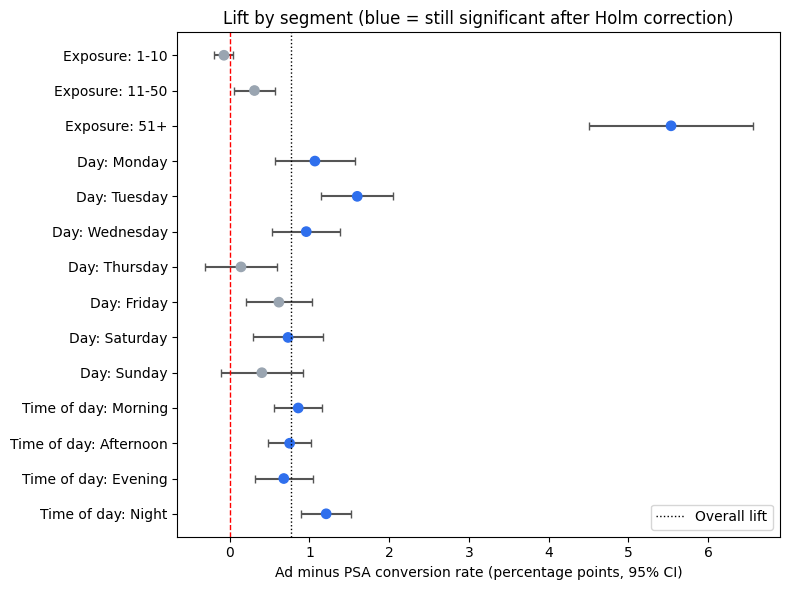

In [41]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_df = seg.iloc[::-1].reset_index(drop=True)
y = np.arange(len(plot_df))
colors = np.where(plot_df["significant_holm"], "#2f6fed", "#9aa5b1")
ax.errorbar(plot_df["diff_pp"], y,
            xerr=[plot_df["diff_pp"] - plot_df["ci_low_pp"], plot_df["ci_high_pp"] - plot_df["diff_pp"]],
            fmt="none", ecolor="#555555", capsize=3, zorder=1)
ax.scatter(plot_df["diff_pp"], y, c=colors, s=45, zorder=2)
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.axvline((ad_converted / ad_total - psa_converted / psa_total) * 100, color="black", linestyle=":", linewidth=1,
           label="Overall lift")
ax.set_yticks(y)
ax.set_yticklabels(plot_df["family"] + ": " + plot_df["segment"])
ax.set_xlabel("Ad minus PSA conversion rate (percentage points, 95% CI)")
ax.set_title("Lift by segment (blue = still significant after Holm correction)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Result after correction:**
- **Still significant (Holm):** exposure 51+, Monday, Tuesday, Wednesday, Saturday, and all four time blocks.
- **No longer significant:** exposure 11 to 50 (adjusted p ≈ 0.12) and Friday (adjusted p ≈ 0.058). Both looked significant before correction.
- **Never significant:** exposure 1 to 10, Thursday, Sunday.

So the overall effect is robust, but claims such as "ads work best on Tuesdays" should be treated cautiously: the confidence intervals for the days overlap heavily.

## 9. Business Impact: Is the Campaign Profitable?

The dataset has no revenue or cost data, so this section uses **illustrative assumptions** that should be replaced with real figures.

| Scenario | Value per conversion |
|---|---|
| Low | ₹100 |
| Base | ₹250 |
| High | ₹500 |

Assumed cost: **₹0.50 per ad impression**, applied to every impression in the Ad group (`total ads`).

**Incremental conversions** = actual Ad conversions minus the conversions we would have expected if the Ad group had converted at the PSA rate. This isolates the conversions caused by the ad.

In [42]:
ad_conversions = ad_converted
psa_rate = psa_converted / psa_total

expected_ad_conversions = ad_total * psa_rate
incremental_conversions = ad_conversions - expected_ad_conversions

# Uncertainty: scale the CI of the rate difference to the Ad group size
diff_lo, diff_hi = confint_proportions_2indep(
    ad_converted, ad_total, psa_converted, psa_total, method="wald"
)
incr_low, incr_high = ad_total * diff_lo, ad_total * diff_hi

print("Actual Ad conversions:", ad_conversions)
print("Expected Ad conversions at PSA rate:", expected_ad_conversions)
print("Estimated incremental conversions:", incremental_conversions)
print(f"95% range: {incr_low:,.0f} to {incr_high:,.0f}")

Actual Ad conversions: 14423
Expected Ad conversions at PSA rate: 10080.017854106443
Estimated incremental conversions: 4342.982145893557
95% range: 3,360 to 5,326


In [43]:
conversion_values = {"Low": 100, "Base": 250, "High": 500}

for scenario, value in conversion_values.items():
    business_value = incremental_conversions * value
    print(scenario, "scenario:", f"₹{business_value:,.2f}")

Low scenario: ₹434,298.21
Base scenario: ₹1,085,745.54
High scenario: ₹2,171,491.07


In [44]:
total_ad_impressions = df.loc[
    df["test group"] == "ad",
    "total ads"
].sum()

ad_cost_per_impression = 0.50

total_ad_cost = total_ad_impressions * ad_cost_per_impression

print("Total Ad impressions:", total_ad_impressions)
print("Assumed cost per impression:", f"₹{ad_cost_per_impression:.2f}")
print("Estimated total ad cost:", f"₹{total_ad_cost:,.2f}")

Total Ad impressions: 14014701
Assumed cost per impression: ₹0.50
Estimated total ad cost: ₹7,007,350.50


In [45]:
ad_cost = total_ad_cost

for scenario, value in conversion_values.items():
    incremental_value = incremental_conversions * value
    net_impact = incremental_value - ad_cost
    roi = (net_impact / ad_cost) * 100

    print(scenario)
    print("Incremental value:", f"₹{incremental_value:,.2f}")
    print("Net impact:", f"₹{net_impact:,.2f}")
    print("ROI:", f"{roi:.2f}%")
    print("-" * 40)

Low
Incremental value: ₹434,298.21
Net impact: ₹-6,573,052.29
ROI: -93.80%
----------------------------------------
Base
Incremental value: ₹1,085,745.54
Net impact: ₹-5,921,604.96
ROI: -84.51%
----------------------------------------
High
Incremental value: ₹2,171,491.07
Net impact: ₹-4,835,859.43
ROI: -69.01%
----------------------------------------


In [46]:
break_even_value = total_ad_cost / incremental_conversions

print("Break-even value per incremental conversion:", f"₹{break_even_value:,.2f}")

Break-even value per incremental conversion: ₹1,613.49


**Interpretation:** at ₹0.50 per impression the campaign loses money in all three scenarios (ROI between -94% and -69%). The cost per *incremental* conversion is about ₹1,613, so every conversion would need to be worth at least that much to break even.

### 9.1 Sensitivity: the cost assumption drives the answer

The ₹0.50 cost is invented, so the more honest question is: *how cheap would impressions need to be for the campaign to pay off?*

scenario,Low,Base,High
cost_per_impression,,,
0.0200,54.9000,287.4000,674.7000
0.0500,-38.0000,54.9000,209.9000
0.1000,-69.0000,-22.5000,54.9000
0.2500,-87.6000,-69.0000,-38.0000
0.5000,-93.8000,-84.5000,-69.0000


Break-even cost per impression (campaign neither gains nor loses):
  Low (₹100 per conversion): ₹0.031
  Base (₹250 per conversion): ₹0.077
  High (₹500 per conversion): ₹0.155


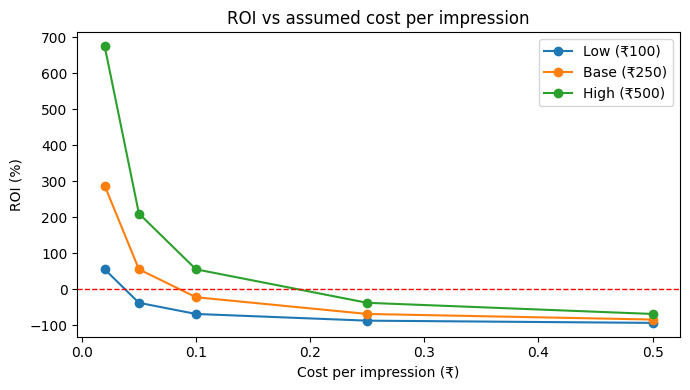

In [47]:
costs = [0.02, 0.05, 0.10, 0.25, 0.50]
rows = []
for c in costs:
    cost = total_ad_impressions * c
    for name, val in conversion_values.items():
        rows.append({"cost_per_impression": c, "scenario": name,
                     "roi_pct": (incremental_conversions * val - cost) / cost * 100})
sens = (pd.DataFrame(rows)
          .pivot(index="cost_per_impression", columns="scenario", values="roi_pct")[["Low", "Base", "High"]])
display(sens.round(1))

print("Break-even cost per impression (campaign neither gains nor loses):")
for name, val in conversion_values.items():
    print(f"  {name} (₹{val} per conversion): ₹{incremental_conversions * val / total_ad_impressions:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
for name in ["Low", "Base", "High"]:
    ax.plot(sens.index, sens[name], marker="o", label=f"{name} (₹{conversion_values[name]})")
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Cost per impression (₹)")
ax.set_ylabel("ROI (%)")
ax.set_title("ROI vs assumed cost per impression")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** the campaign breaks even at roughly ₹0.03, ₹0.08 and ₹0.15 per impression in the Low, Base and High value scenarios. At ₹0.05 per impression and ₹250 per conversion, ROI would be about +55%. So the verdict flips depending on the real cost per impression and the real value per conversion, which is exactly the information the business must supply before deciding.

## 10. Conclusion and Recommendations

**What the data proves**
- The experiment is valid (SRM passed) and well powered (MDE 0.26 pp vs 0.77 pp observed).
- The Ad group had a higher conversion rate than the PSA control group: +0.77 percentage points (+43% relative). The difference is statistically significant and the bootstrap interval supports the same conclusion. A causal interpretation depends on valid random assignment and the experiment design.
- The Ad group has a higher observed conversion rate in all four time blocks. After Holm correction, the segment differences that remain significant are exposure 51+, Monday, Tuesday, Wednesday, Saturday, and all four time blocks. The 11–50 exposure bucket and Friday do not survive correction; Thursday, Sunday, and exposure 1–10 are not significant.

**What it does not prove**
- That more ads cause more conversions (exposure is post-treatment).
- That the campaign is profitable. This depends on real cost and value data that the dataset does not include.
- Anything about ad vs *no* ad, since the control group saw PSAs.

**Recommended actions**
1. Obtain actual cost per impression and margin per conversion, then plug them into Section 9. Continue the campaign only if value per incremental conversion exceeds the cost per incremental conversion (₹1,613 under the current assumptions).
2. Run a randomised frequency-cap test (for example 10 vs 30 vs uncapped impressions) to find out whether heavy exposure truly drives conversions.
3. Review spend on light-exposure users (1 to 10 ads), where no significant lift was found.
4. Next time, record pre-experiment user attributes so that segment balance can be checked properly.

**Method notes:** Wald intervals are accurate at this sample size; PSA group size (23,524) is the main limit on precision; multiple-testing correction applied to the 14 segment tests only.